In [ ]:
import numpy as np 
import pandas as pd
from sklearn.feature_selection import SelectKBest,f_regression,RFE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report 
from sklearn.tree import DecisionTreeClassifier 




#Question 1.1--------------------------------|


df = pd.read_csv('machine_service_risk.csv')
target = df["Major_Service_Required"]


df = df.drop(columns=["Asset_ID","Major_Service_Required"])





df['Maintenance_Plan'] = df['Maintenance_Plan'].fillna("Unknown")
df['Intermittent_Shutdown'] = df['Intermittent_Shutdown'].map({'Yes':1,'No':0})
df['Dust_Exposure_Level'] = df['Dust_Exposure_Level'].map({'High':1,'Low':0})
df['Service_Contract'] = df['Service_Contract'].map({'Standard':1,'Extended':0})

df = pd.get_dummies(df ,columns=['Operating_Zone','Maintenance_Plan'], dtype=int)
scaler_potential = ['Average_Load_Tonnes','Equipment_Age_Months','Daily_Operating_Hours','Weekly_Idle_Hours','Lubrication_Quality_Score']

X_train,X_test,y_train,y_test = train_test_split(df,target,test_size=0.3,random_state=42)

scaler = StandardScaler()
Scaler_X_train = scaler.fit_transform(X_train)
Scaler_X_test = scaler.transform(X_test)


#Question 1.2--------------------------------|


k= 8 
selector =SelectKBest(score_func=f_regression,k=k)
X_selected = selector.fit_transform(df, target)


selected_indices = np.argsort(selector.scores_)[::-1][:k]
selected_features = df.columns[selected_indices]

print("SelectKBest Features:")


for i in range(len(selected_features)):

    print(selected_features[i],"Score: ", selected_indices[i])
    



#Question 1.3--------------------------------|

model = LogisticRegression(max_iter=3000)
selector = RFE(estimator=model, n_features_to_select=8)
selector.fit(X_train, y_train)
rfe_results = X_train.columns[selector.support_]
print("RFE Features:")
for i in range(len(rfe_results)):
    print(rfe_results[i])



#Question 2.1 & 2.2 -------------------------------|


RFE_features = ['Mechanical_Condition_Score', 'Maintenance_Compliance_Score',     'Error_Log_Alert', 'Sensor_Health_Score', 'Irregular_Vibration_Alert',       'Cooling_Efficiency_Score', 'Coolant_Temperature_C',      'Maintenance_Plan_Unknown']
X_train,X_test,y_train,y_test = train_test_split(df[RFE_features],target,test_size=0.25,random_state=42,    stratify=target)

scaler = StandardScaler()
Scaler_X_train = scaler.fit_transform(X_train)
Scaler_X_test = scaler.transform(X_test)

"""
Logistic regression model

"""

regression_model =  LogisticRegression(max_iter=10000)
regression_model.fit(Scaler_X_train, y_train)
y_rfe_pred = regression_model.predict(Scaler_X_test)

print("Logistic regression Accuracy:", accuracy_score(y_test, y_rfe_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_rfe_pred))
print("\nClassification Report:\n", classification_report(y_test, y_rfe_pred))

"""
Decision tree model

"""

decision_tree = DecisionTreeClassifier()
decision_tree.fit(Scaler_X_train, y_train)
y_dt_pred = decision_tree.predict(Scaler_X_test)


print("Decision tree Accuracy:", accuracy_score(y_test, y_dt_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_dt_pred))
print("\nClassification Report:\n", classification_report(y_test, y_dt_pred))













SelectKBest Features:
Mechanical_Condition_Score Score:  21
Maintenance_Compliance_Score Score:  24
Error_Log_Alert Score:  22
Sensor_Health_Score Score:  20
Irregular_Vibration_Alert Score:  23
Cooling_Efficiency_Score Score:  7
Coolant_Temperature_C Score:  18
Maintenance_Plan_Unknown Score:  37


/Users/joshuasingrew/Desktop/GitHub/striva-landing/Ai_project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/joshuasingrew/Desktop/GitHub/striva-landing/Ai_project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also w

RFE Features:
Electrical_Fault_History
Mechanical_Condition_Score
Error_Log_Alert
Irregular_Vibration_Alert
Maintenance_Compliance_Score
Operating_Zone_North
Operating_Zone_Remote
Maintenance_Plan_Premium
Logistic regression Accuracy: 0.8364312267657993

Confusion Matrix:
 [[306  42]
 [ 46 144]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.88      0.87       348
           1       0.77      0.76      0.77       190

    accuracy                           0.84       538
   macro avg       0.82      0.82      0.82       538
weighted avg       0.84      0.84      0.84       538

Decision tree Accuracy: 0.9070631970260223

Confusion Matrix:
 [[322  26]
 [ 24 166]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93       348
           1       0.86      0.87      0.87       190

    accuracy                           0.91       538
   macro avg       0.9

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


df = pd.read_csv("grid_restoration.csv")

print(df.isnull().sum())
y = df[["Restoration_Time_Minutes"]]
df = df.drop(columns=["Incident_ID", "Restoration_Time_Minutes"])


df["Technician_Experience_Years"] = df["Technician_Experience_Years"].fillna(
    df["Technician_Experience_Years"].median()
)

for col in ["Fault_Category", "Grid_Load_Level", "Dispatch_Window"]:
  df[col] = df[col].fillna(df[col].mode()[0])


load_mapping = {"Low": 0, "Medium": 1, "High": 2}
df["Grid_Load_Level"] = df["Grid_Load_Level"].map(load_mapping)

df_encoded = pd.get_dummies(
    df, columns=["Fault_Category", "Dispatch_Window", "Crew_Type"], drop_first=True
)

bool_cols = df_encoded.select_dtypes(include=["bool"]).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    df_encoded, y, test_size=0.20, random_state=42
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


def compute_cost(X,y,theta):
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return cost

def batch_gradient_descent(X, y, theta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for _ in range(iterations):
        gradients = (1 / m) * X.T.dot(X.dot(theta) - y)
        theta = theta - learning_rate * gradients
        cost_history.append(compute_cost(X,y,theta))

    return theta ,cost_history
  




X_train_array = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
theta = np.zeros(X_train_array.shape[1])

theta ,cost_history = batch_gradient_descent(
    X_train_array,
    y_train.values.ravel(),
    theta,
    learning_rate=0.1,
    iterations=1000
)

X_test_array = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

y_train_pred = X_train_array.dot(theta)

y_pred = X_test_array.dot(theta)

print()
print("Train")
print("mean sqaured train ",mean_squared_error(y_train,y_train_pred))
print("mean absolute error ",mean_absolute_error(y_train,y_train_pred))
print("r2 train ",r2_score(y_train,y_train_pred))

print()
print("Test")
print("mean sqaured test ",mean_squared_error(y_test,y_pred))
print("mean absolute error ",mean_absolute_error(y_test,y_pred))
print("r2 test ",r2_score(y_test,y_pred))
print()

print("Initial cost:", cost_history[0])
print("Final cost:", cost_history[-1])
print("Cost at iteration 1000:", cost_history[999])
print("Cost at iteration 5000:", cost_history[-1])

plt.plot(cost_history)
plt.title("Batch Gradient Descent - Cost History")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.grid()
plt.show()




Average Silhouette Score: 0.2935
Number of buildings in each cluster:
Cluster
0    63
1    48
2    67
Name: count, dtype: int64
  Building_ID  Cluster  Silhouette_Score
0     BLD-001        2          0.296689
1     BLD-002        2          0.212621
2     BLD-003        2          0.181616
3     BLD-004        0          0.410444
4     BLD-005        1          0.481040


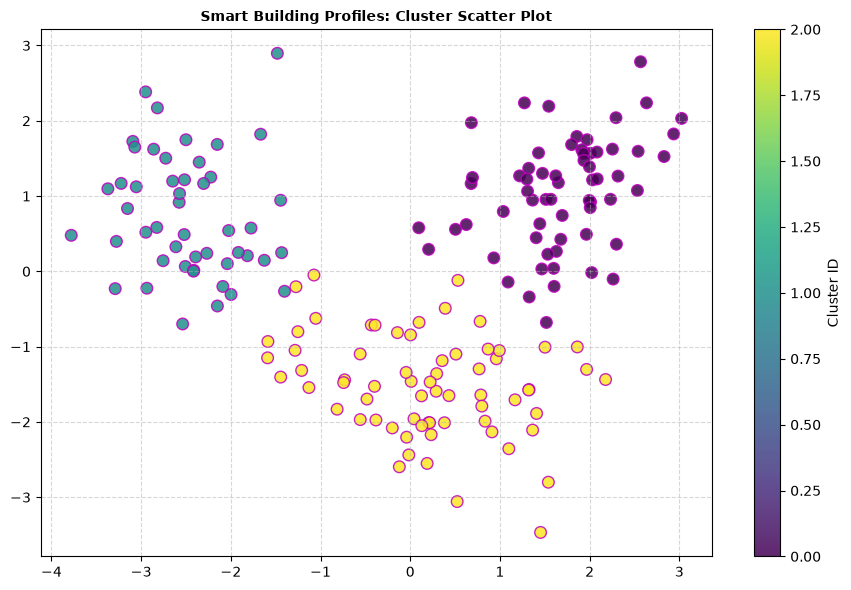

         Avg_Indoor_Temperature_C  Daily_HVAC_Runtime_Hours  \
Cluster                                                       
0                       20.179683                  4.985238   
1                       19.665000                  7.082500   
2                       18.744328                  4.862313   

         Occupancy_Density_per_1000m2  Heating_Setpoint_C  \
Cluster                                                     
0                           49.390476           19.274762   
1                           48.770833           20.456250   
2                           44.361194           19.952537   

         Insulation_Performance_Score  Lighting_Efficiency_Index  \
Cluster                                                            
0                            6.698413                  53.507937   
1                            4.342917                  34.229167   
2                            5.441791                  52.347761   

         Ventilation_Rate_ACH  Solar_

In [7]:
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_samples, silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


df = pd.read_csv('smart_building_profiles.csv')

standard_cols = [
    'Avg_Indoor_Temperature_C', 'Daily_HVAC_Runtime_Hours',
 'Occupancy_Density_per_1000m2', 'Heating_Setpoint_C',
 'Insulation_Performance_Score', 'Lighting_Efficiency_Index',
 'Ventilation_Rate_ACH'
]

robust_cols = [
 'Solar_Gain_Index', 'Peak_Demand_kW',
 'Monthly_Water_Use_m3', 'Annual_Energy_Use_kWh_m2'
]

minmax_cols = [
 'Window_to_Wall_Ratio', 'Equipment_Diversity_Index'
]

preprocessor = ColumnTransformer(
transformers=[
('std', StandardScaler(), standard_cols),
 ('robust', RobustScaler(), robust_cols),
 ('minmax', MinMaxScaler(), minmax_cols)
 ],
 remainder='passthrough'
)


df_clean = df.drop(columns=['Building_ID'])



kmeans_pipeline = Pipeline(steps=[("preprocessor",preprocessor),("clusterer",KMeans(n_clusters=3, random_state=42))])
cluster_labels = kmeans_pipeline.fit_predict(df_clean)

X_scaled = kmeans_pipeline.named_steps["preprocessor"].transform(df_clean)
avg_silhouette = silhouette_score(X_scaled , cluster_labels)
print(f"Average Silhouette Score: {avg_silhouette:.4f}")

sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)


df["Silhouette_Score"] = sample_silhouette_values
df["Cluster"] = cluster_labels
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of buildings in each cluster:")
print(cluster_counts)
print(df[["Building_ID", "Cluster", "Silhouette_Score"]].head())


pca_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor), 
        (
            "pca",
            PCA(n_components=2, random_state=42),
        ),  
    ]
)

X_reduced = pca_pipeline.fit_transform(df_clean)
df["PC1"] = X_reduced[:, 0]
df["PC2"] = X_reduced[:, 1]


plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["PC1"],
    df["PC2"],
    c=df["Cluster"],
    cmap="viridis",
    s=70,
    alpha=0.85,
    edgecolor="m",
    linewidth=1,
)
plt.colorbar(scatter, label="Cluster ID")
plt.title(
    "Smart Building Profiles: Cluster Scatter Plot",
    fontsize=10,
    fontweight="bold",
)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

scaled_centers = kmeans_pipeline.named_steps["clusterer"].cluster_centers_
orgl_features_list = standard_cols + robust_cols + minmax_cols
org_centers = (
    kmeans_pipeline.named_steps["preprocessor"]
    .named_transformers_["std"]  
    .inverse_transform(scaled_centers[:, : len(standard_cols)])
)


cluster_profiles = df.groupby("Cluster")[standard_cols + robust_cols].mean()
print(cluster_profiles)

